# Fig. 7i: manifold dimension of the ground truth and of the sorted populations (evoked model)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel i of the paper: manifold dimension (average dimensionality of the embedding subspace spanned by the manifolds evoked by the repetitions of each stimulus direction) of the ground truth neurons, of the sorted single-units of each spike sorter and of the multiunit threshold crossing. Source data and svg are saved in figures/8_source_data/fig7i/.

**method (as in the paper's notebook fig7_B_info_capacity_by_sorter_revised.ipynb)**
* the dimension of each population is computed on 200 bootstraps of the neurons or units (population responses to the 360 stimulus directions, 200 latents, `neural_manifolds_replicaMFT`)
* the 200 bootstrapped dimensions of each population are read from the csv files of the paper (`igeometrics_by_sorter.csv`, `igeometrics_thresh_crossing.csv`); they are **not recomputed** here (the analysis needs the `mftma` package)
* box plots (notch, 200 bootstraps); red dashed line: median dimension of the ground truth
* comparison with the ground truth: two-sample t-test between the 200 bootstrapped dimensions (as in the paper's notebook)

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
import seaborn as sns
from scipy.stats import ttest_ind

# paths (bootstrapped manifold capacities of the ground truth and of the sorted populations, evoked simulation, 1 hour)
NEURAL_CODE_PATH = "dataset/01_intermediate/neural_code/npx_evoked/"
IGEOM_SORT = NEURAL_CODE_PATH + "igeometrics_by_sorter.csv"
IGEOM_TC = NEURAL_CODE_PATH + "igeometrics_thresh_crossing.csv"

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the bootstrapped dimensions

In [2]:
%%time

igeom_df = pd.read_csv(IGEOM_SORT)
igeom_tc_df = pd.read_csv(IGEOM_TC)
igeom_df = pd.concat([igeom_df, igeom_tc_df[igeom_tc_df["Sorter"] == "thresh-crossing"]], axis=0, ignore_index=True)

# populations in the order of the figure
NAMES = {"ground_truth": "Ground\ntruth", "KS4": "KS4", "KS3": "KS3", "KS2.5": "KS2.5", "KS2": "KS2", "KS": "KS", "HS": "HS", "thresh-crossing": "TC"}
df = igeom_df[igeom_df["Sorter"].isin(NAMES)][["Sorter", "Dimension"]].copy()
df["population"] = df["Sorter"].map(NAMES)
df["bootstrap"] = df.groupby("Sorter").cumcount()
df = df.set_index("Sorter").loc[list(NAMES)].reset_index(drop=True)[["population", "bootstrap", "Dimension"]].rename(columns={"Dimension": "manifold_dimension"})
print(df.groupby("population", sort=False)["manifold_dimension"].agg(["count", "median"]).round(3))

               count  median
population                  
Ground\ntruth    200  12.477
KS4              200  13.075
KS3              200  13.843
KS2.5            200  12.848
KS2              200  12.355
KS               200   7.922
HS               200  13.194
TC               200   8.610
CPU times: user 7.12 ms, sys: 12 µs, total: 7.13 ms
Wall time: 7.15 ms


## Dimension of each sorted population against the ground truth

In [3]:
gt = df[df["population"] == "Ground\ntruth"]["manifold_dimension"]
rows = []
for name in list(NAMES.values())[1:]:
    r = df[df["population"] == name]["manifold_dimension"]
    t, p = ttest_ind(gt, r)
    rows.append(dict(population=name, median_dimension=r.median(), change_percent=100 * (r.mean() - gt.mean()) / gt.mean(), t_statistic=t, p_value=p))
stats = pd.DataFrame(rows)
display(stats.round(4))
sorters = stats[stats["population"] != "TC"]
print("average change of the dimension over the 6 spike sorters (%):", round(sorters["change_percent"].mean(), 1), "| without KS:", round(sorters[sorters["population"] != "KS"]["change_percent"].mean(), 1))

,population,median_dimension,change_percent,t_statistic,p_value
0,KS4,13.0754,4.9896,-27.3495,0.0
1,KS3,13.8426,11.2263,-59.9486,0.0
2,KS2.5,12.8485,3.2036,-18.0725,0.0
3,KS2,12.3553,-0.8000,4.6187,0.0
4,KS,7.9224,-36.3532,234.9732,0.0
5,HS,13.1938,5.8318,-31.0131,0.0
6,TC,8.6098,-30.8941,194.6155,0.0


average change of the dimension over the 6 spike sorters (%): -2.0 | without KS: 4.9


## Plot, same as the paper's panel h

In [4]:
def plot_source_data(df: pd.DataFrame):
    """Box plots (notched) of the manifold dimension of the 200 bootstraps of each population; red dashed line: median of the ground truth"""

    fig, ax = plt.subplots(1, 1, figsize=(1.5, 1))
    gt_median = df[df["population"] == "Ground\ntruth"]["manifold_dimension"].median()
    ax.hlines(xmin=-0.5, xmax=7.5, y=gt_median, color="red", linestyle="--", linewidth=1.2)
    BOXPLOT_PMS = {"notch": True, "gap": 0.3, "width": 0.7, "linewidth": 0.5,
                   "flierprops": {"marker": "o", "markerfacecolor": "k", "markersize": 1.5, "markeredgewidth": 0.5}}
    ax = sns.boxplot(ax=ax, data=df, x="population", y="manifold_dimension", palette=["black"], **BOXPLOT_PMS)

    # labels
    ax.set_ylabel("Manifold dimension")
    ax.set_title("200 bootstraps", fontsize=6)
    ax.set_xlabel("Spike sorter")

    # disconnected axes
    ax.set_xlim(left=-1)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.spines["left"].set_position(("axes", -0.05))
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")      # after the spines, which reset the tick labels
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 154 ms, sys: 6.97 ms, total: 161 ms
Wall time: 161 ms


/tmp/ipykernel_638898/1822331490.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(ax=ax, data=df, x="population", y="manifold_dimension", palette=["black"], **BOXPLOT_PMS)


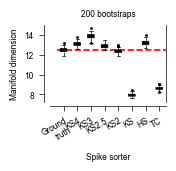

In [5]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig7i", exist_ok=True)
plt.savefig("figures/8_source_data/fig7i/fig7i.svg", bbox_inches="tight", **savefig_cfg)

# save source data (sheet 1: dimension of the 200 bootstraps of each population; sheet 2: comparison with the ground truth)
with pd.ExcelWriter("figures/8_source_data/fig7i/fig7i.xlsx") as writer:
    df.to_excel(writer, sheet_name="dimension_bootstraps", index=False)
    stats.to_excel(writer, sheet_name="vs_ground_truth", index=False)

## Check: replot from the saved source data

CPU times: user 116 ms, sys: 43 µs, total: 116 ms
Wall time: 115 ms


/tmp/ipykernel_638898/1822331490.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(ax=ax, data=df, x="population", y="manifold_dimension", palette=["black"], **BOXPLOT_PMS)


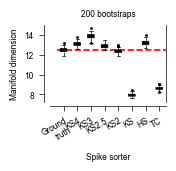

In [6]:
%%time

df = pd.read_excel("figures/8_source_data/fig7i/fig7i.xlsx", sheet_name="dimension_bootstraps")
fig, ax = plot_source_data(df)